# Task 2

## Setting up

In [5]:
# import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import cross_val_score, KFold

In [7]:
# read in the data
train_in = pd.read_csv("data/train_in.csv")
train_in = train_in.to_numpy()

train_out = pd.read_csv("data/train_out.csv")
train_out = train_out.to_numpy() # these are the labels for training data
train_out = train_out.reshape(-1)

test_in = pd.read_csv("data/test_in.csv")
test_in = test_in.to_numpy()

test_out = pd.read_csv("data/test_out.csv")
test_out = test_out.to_numpy()
test_out = test_out.reshape(-1) # these are the labels for testing data

## Creating the functions

In [15]:
# Making all the MLP functions train, predict, evaluate, plot cm
def train_mlp(data, labels, n_features, epochs):
    W = np.zeros((n_features, 10))
    for epoch in range(epochs):
        for i in range(len(data)):
            x = data[i].reshape(-1)
            scores = x @ W
            y_pred = scores.argmax()

            if y_pred != labels[i]:
                W[:, labels[i]] += x
                W[:, y_pred] -= x   

    return W # weight matrix

def predict_mlp(x, W):
    return (x @ W).argmax()

def evaluate_mlp(data, labels, W):
    predictions = np.array([predict_mlp(x, W) for x in data])
    return np.mean(predictions == labels) # accuracy

def cm_mlp(data, labels, W):
    predictions = np.array([predict_mlp(x, W) for x in data])
    cm = confusion_matrix(labels, predictions)
    plt.xlabel("Predicted labels")
    plt.ylabel("True labels")
    plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
    plt.title(f"Confusion matrix")
    plt.colorbar()
    plt.show()

## Performance of 256x10 on test set

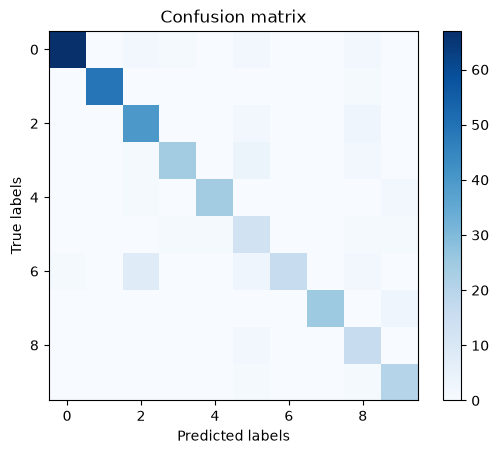

Fold 1 - Validation Accuracy: 0.8596


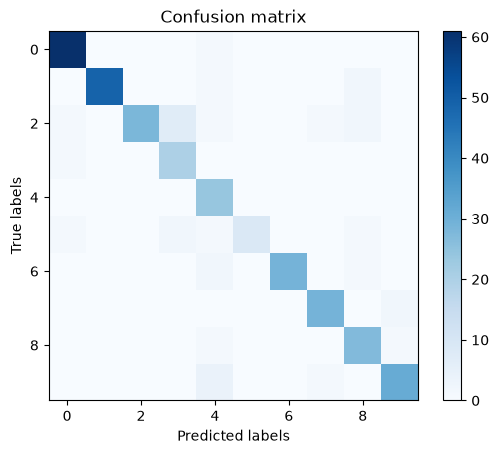

Fold 2 - Validation Accuracy: 0.9003


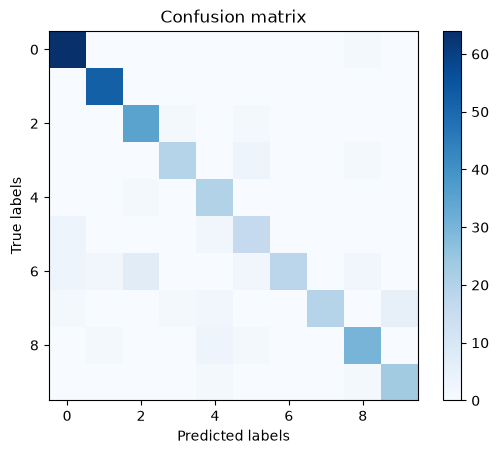

Fold 3 - Validation Accuracy: 0.8680


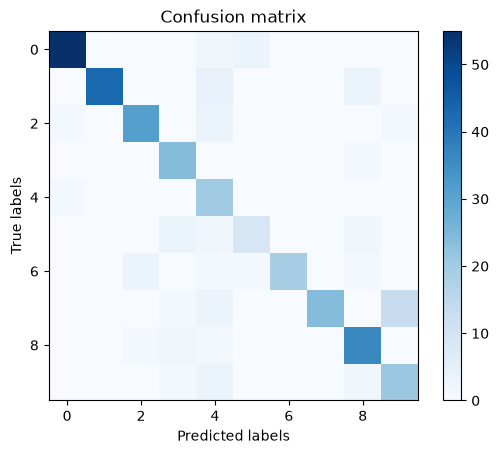

Fold 4 - Validation Accuracy: 0.8270


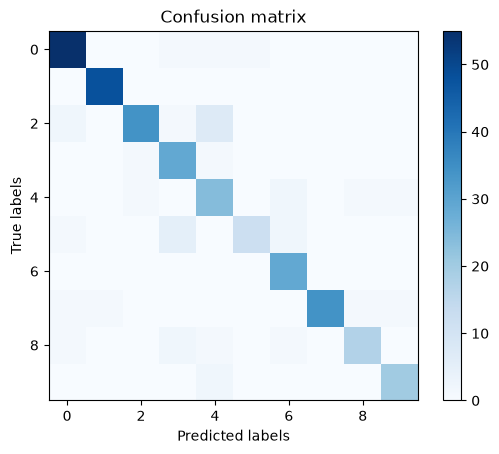

Fold 5 - Validation Accuracy: 0.8856
Average Validation Accuracy: 0.8681


In [16]:
# 5-fold CV
def cross_validation(data, labels, n_features, epochs):
    N = len(labels)
    indices = np.arange(N)
    np.random.shuffle(indices)

    train_in_shuffled = data[indices]
    train_out_shuffled = labels[indices]

    folds = np.array_split(indices, 5)
    accuracies = np.zeros(5)

    for k in range(5):
        validation_indices = folds[k]
        training_indices = np.concatenate([folds[i] for i in range(5) if i != k])

        x_train = train_in_shuffled[training_indices]
        y_train = train_out_shuffled[training_indices]

        x_val = train_in_shuffled[validation_indices]
        y_val = train_out_shuffled[validation_indices]

        # Train the model on the training data
        weights = train_mlp(x_train, y_train, n_features, epochs)

        # Evaluate the model on the validation data
        val_accuracy = evaluate_mlp(x_val, y_val, weights)
        cm_mlp(x_val, y_val, weights)

        accuracies[k] = val_accuracy

        print(f"Fold {k + 1} - Validation Accuracy: {val_accuracy:.4f}")

    print(f"Average Validation Accuracy: {np.mean(accuracies):.4f}")

cross_validation(train_in, train_out, 256, 1)

Test Accuracy: 0.7467


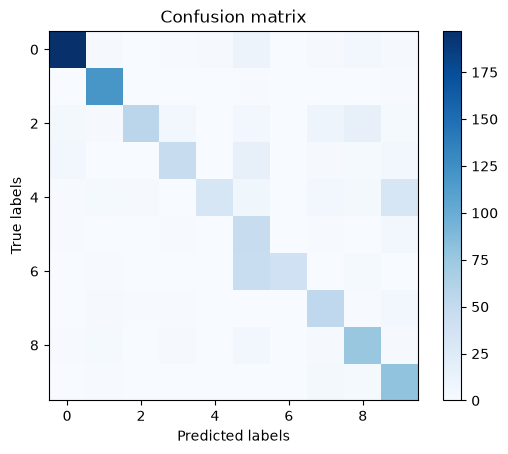

In [17]:
# evaluate performance on test data + plot alongside training data performance
final_weights = train_mlp(train_in, train_out, 256, 1)
test_accuracy = evaluate_mlp(test_in, test_out, final_weights)
print(f"Test Accuracy: {test_accuracy:.4f}")
cm_mlp(test_in, test_out, final_weights)

Depending on the seed, the average validation accuracy from the cross-validation is around 0.86 and the test accuracy is around 0.75.
This is just based on the 256 features x 10 classes, where the weight matrix has been filled with zeroes.

## Performance of 257x10 (added bias) on test set

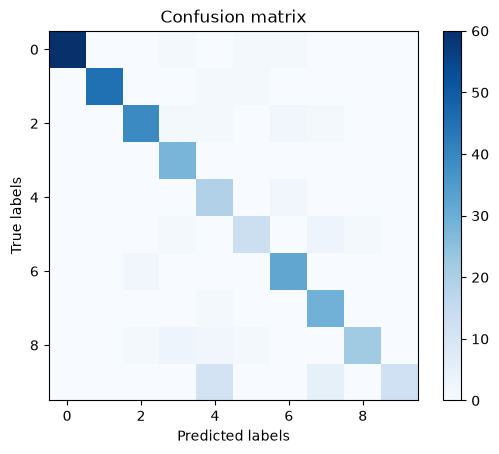

Fold 1 - Validation Accuracy: 0.8743


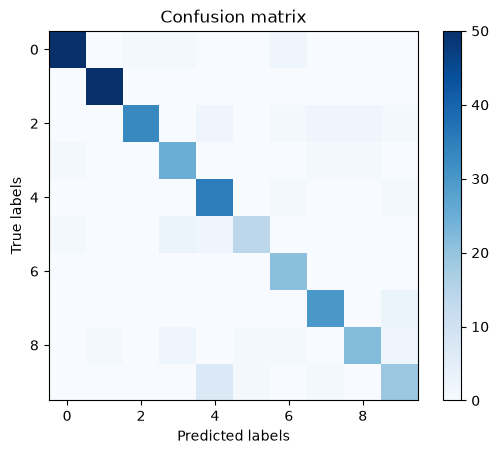

Fold 2 - Validation Accuracy: 0.8768


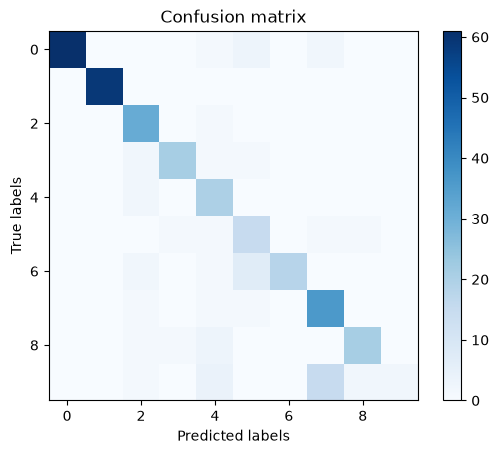

Fold 3 - Validation Accuracy: 0.8328


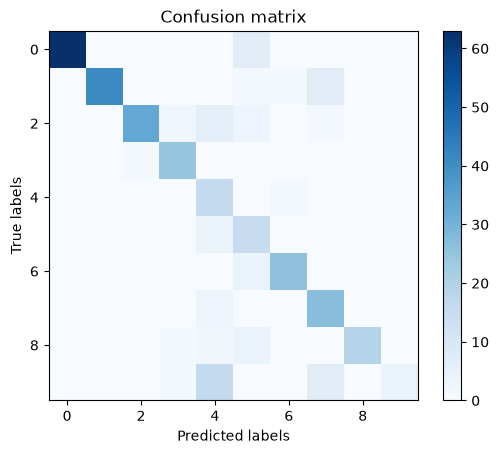

Fold 4 - Validation Accuracy: 0.7889


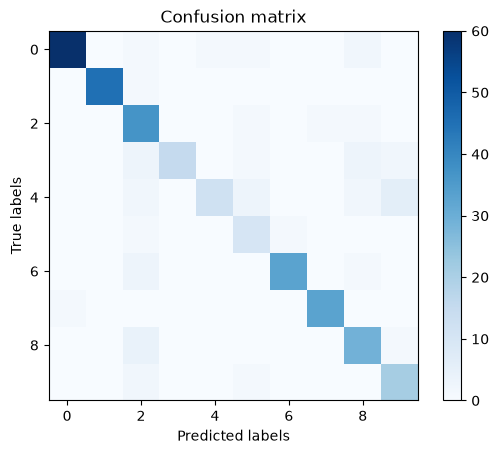

Fold 5 - Validation Accuracy: 0.8651
Average Validation Accuracy: 0.8476
Test Accuracy: 0.8078


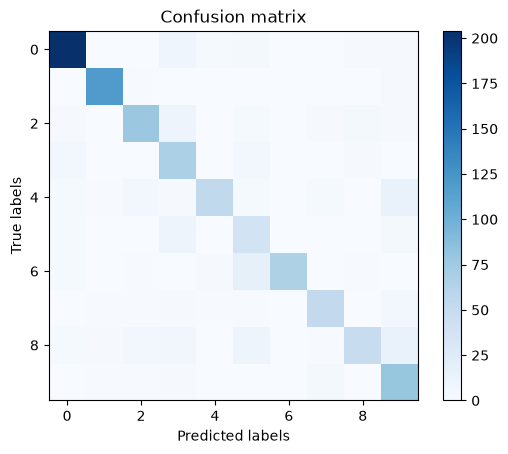

In [18]:
# adding bias
bias_train = np.ones((train_in.shape[0], 1))
bias_test = np.ones((test_in.shape[0], 1))

train_in_bias = np.hstack((train_in, bias_train))
test_in_bias = np.hstack((test_in, bias_test))

# 5-fold CV to get an idea of the accuracy
cross_validation(train_in_bias, train_out, 257, 1)

b_final_weights = train_mlp(train_in_bias, train_out, 257, 1)
b_test_accuracy = evaluate_mlp(test_in_bias, test_out, b_final_weights)
print(f"Test Accuracy: {b_test_accuracy:.4f}")
cm_mlp(test_in_bias, test_out, b_final_weights)

Depending on the seed, the average validation accuracy from the cross-validation is around 0.85 and the test accuracy is around 0.81.
This is based on the 257 features x 10 classes, where the weight matrix has been filled with zeroes. The 257th feature is filled with 1's to introduce bias, like the assignment suggested. The test accuracy has increased compared to the 256 features prediction.

## Another try with 10 epochs

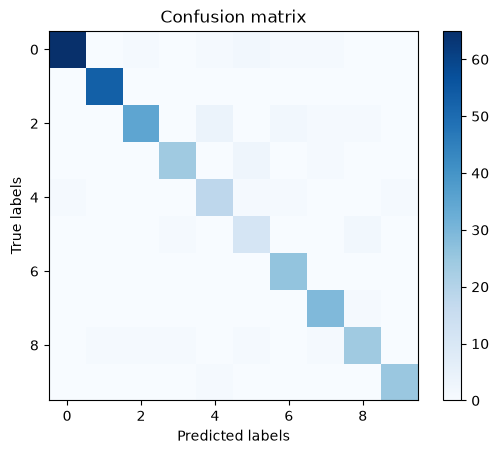

Fold 1 - Validation Accuracy: 0.9064


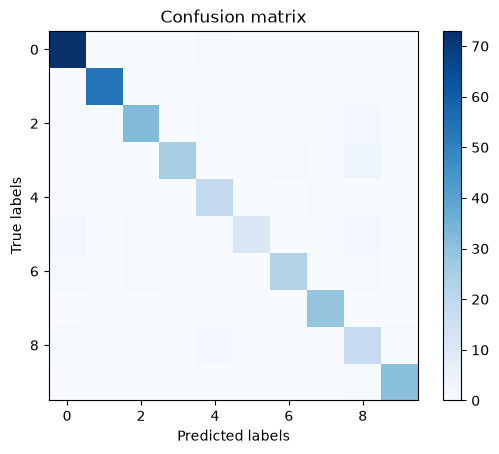

Fold 2 - Validation Accuracy: 0.9238


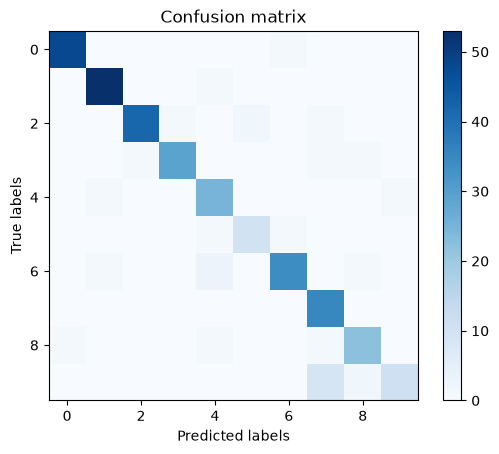

Fold 3 - Validation Accuracy: 0.9062


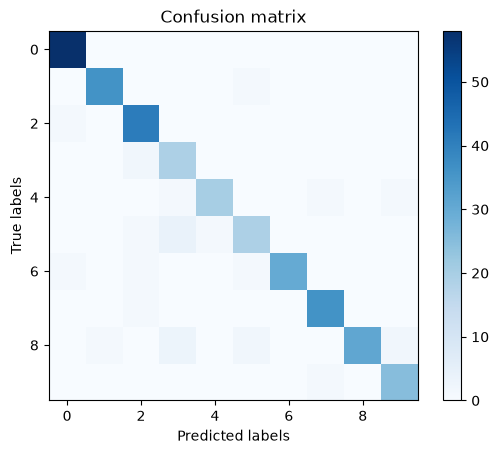

Fold 4 - Validation Accuracy: 0.9238


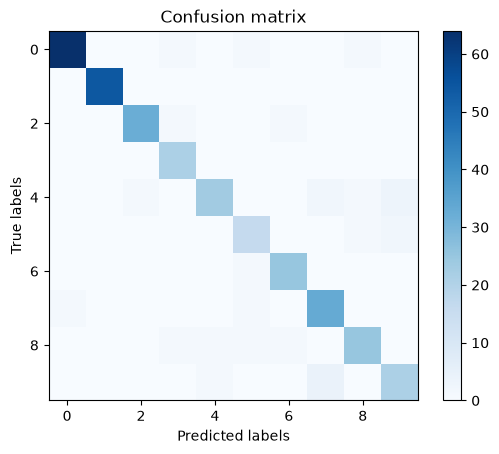

Fold 5 - Validation Accuracy: 0.9208
Average Validation Accuracy: 0.9162
Test Accuracy: 0.8438


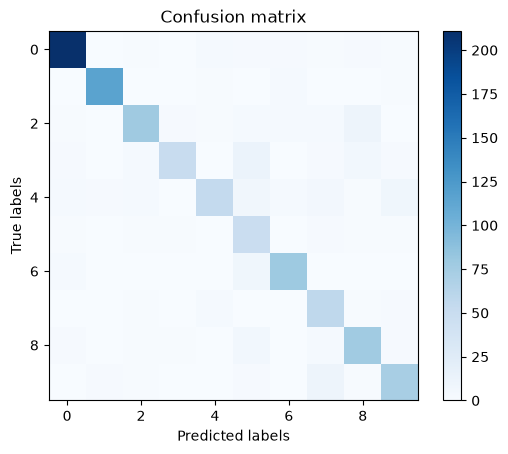

In [19]:
# 5-fold CV to get an idea of the accuracy
cross_validation(train_in_bias, train_out, 257, 10)

e_final_weights = train_mlp(train_in_bias, train_out, 257, 10)
e_test_accuracy = evaluate_mlp(test_in_bias, test_out, e_final_weights)
print(f"Test Accuracy: {e_test_accuracy:.4f}")
cm_mlp(test_in_bias, test_out, e_final_weights)

For this third try, I have changed the # of epochs from 1 to 10. This resulted in a better validation accuracy of around 0.92 and a test accuracy of 0.84. I'm pretty happy with this result, as it seems to be more stable than the first two tries.

Compared to the NMC and KNN from task 1, the MLP seems to land right in the middle of the test accuracies:
* NMC: 0.798
* MLP: 0.844
* KNN: 0.905